<a href="https://colab.research.google.com/github/EmiBonClay/orchidaceae_cl/blob/main/Orchidaceae_cl_hub.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Orchidaceae
Chile continental

Participa del [VII Monitoreo de Orquídeas Chilenas 2026-27]('https://inaturalist.mma.gob.cl/projects/vii-monitoreo-de-orquideas-chilenas-2026-27?tab=observers')

Te invitamos a ser parte de la séptima versión de este proyecto de Ciencia Ciudadana, para que juntos podamos conservar las orquídeas chilenas! El objetivo es levantar información sobre la distribución, el tamaño de sus poblaciones y las posibles amenazas de nuestras orquídeas. Este monitoreo se realizará cada año para ir evaluando el estado de las poblaciones de orquídeas en el tiempo.
El Monitoreo Nacional de Orquídeas Chilenas Temporada 2026-2027 es organizado por el Centro de Conservación de Orquídeas Chilenas (CECORCH) junto al Ministerio de Medio Ambiente y la Red Chilena de Jardínes Botánicos.
Para más información, síguenos en ig: @centro_cecorch

## [Monitoreo de Orquídeas](https://cecorch.cl/monitoreo.html)

"El plan de monitoreo se enmarca dentro del primer objetivo del eje de conservación, el cual es determinar el estado de conservación y las amenazas de cada una de las poblaciones de las 60 especies de orquídeas que no han sido evaluadas en Chile. Para ello, este trabajo se desarrollará bajo el concepto de ciencia ciudadana, el cual busca involucrar a la comunidad en el levantamiento de información a través de un plan de monitoreo, donde las personas inscritas de forma voluntaria se comprometen a monitorear una población de orquídeas al menos una vez.

Esta metodología incluye etapas formativas a los monitores que lo requieran, principalmente relacionadas al reconocimiento de especies, donde se espera que una asociación con la comunidad local genere un impacto mayor y duradero en el programa de monitoreo, que los proyectos de carácter privados o gubernamentales que no involucren a la población."

https://www.youtube.com/watch?v=wzE1d69_4wo

https://notebooklm.link.google/xQVMfTfQs5rV

### Líneas de investigación

 *   Evolución de las especies de orquídeas chilenas,
 *   Las interacciones de las orquídeas con polinizadores
 *   Asociaciones con hongos micorrícicos.

### [Bibliografía](https://drive.google.com/drive/u/0/folders/1cwf3k5tLvOSa_dhm5z0fBYmy9w9oetaF)

### Librerías

Dependencias:

In [ ]:
!pip install pygbif
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.4/101.4 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 65.8 MB/s eta 0:00:00


In [ ]:
import warnings
warnings.filterwarnings('ignore')

Librerías importadas

In [ ]:
import pandas as pd ## manipulación de dataframes
from pygbif import occurrences as occ ## módulo de ocurrencias de GBIF
from pygbif import species ## módulo de especies GBIF
import plotly.express as px

import numpy as np
import os

import matplotlib.pyplot as plt
import seaborn as sns

import skimage.io

import requests
from bs4 import BeautifulSoup


from cv2 import imread
import cv2
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt


Variables de sesión

In [ ]:
# @title
os.environ['GBIF_USER']="user"
os.environ['GBIF_PWD']=""
os.environ['GBIF_EMAIL']="mail@mail.com"

Exploración de familia

In [ ]:
species.name_backbone('Orchidaceae',taxonRank='family')

{'usage': {'key': 'DPL',
  'name': 'Orchidaceae Juss.',
  'canonicalName': 'Orchidaceae',
  'authorship': 'Juss.',
  'rank': 'FAMILY',
  'code': 'BOTANICAL',
  'status': 'ACCEPTED',
  'type': 'SCIENTIFIC',
  'formattedName': '<i>Orchidaceae</i> Juss.'},
 'classification': [{'key': 'CS5HF', 'name': 'Eukaryota', 'rank': 'DOMAIN'},
  {'key': 'P', 'name': 'Plantae', 'rank': 'KINGDOM'},
  {'key': 'CMQ8S', 'name': 'Pteridobiotina', 'rank': 'SUBKINGDOM'},
  {'key': 'TP', 'name': 'Tracheophyta', 'rank': 'PHYLUM'},
  {'key': 'L2L', 'name': 'Liliopsida', 'rank': 'CLASS'},
  {'key': 'SP', 'name': 'Asparagales', 'rank': 'ORDER'},
  {'key': 'DPL', 'name': 'Orchidaceae', 'rank': 'FAMILY'}],
 'diagnostics': {'matchType': 'EXACT',
  'confidence': 95,
  'timeTaken': 8,
  'timings': {'nameNRank': 0,
   'sciNameMatch': 8,
   'nameParse': 0,
   'luceneMatch': 8}},
 'synonym': False,
 'left': 827022,
 'right': 872365}

La consulta al módulo search sólo devuelve 300 registros como máximo.

In [ ]:
# Search for occurrences of Orchidaceae (taxonKey: 7689) in Chile (country code: CL)
chile_orchids = occ.search(taxonKey=7689, country='CL', limit=300)

# Convert results to a DataFrame for easier reading
import pandas as pd
df_occurrences = pd.DataFrame(chile_orchids['results'])

# Extract unique species names observed in Chile
if 'species' in df_occurrences.columns:
    df_species = df_occurrences[['species', 'scientificName', 'decimalLatitude', 'decimalLongitude']].dropna(subset=['species']).drop_duplicates(subset=['species'])
    print(f"Found {len(df_species)} unique orchid species in the retrieved records:")
    display(df_species.head(10))
else:
    print("No species column found in the occurrences data.")

Found 27 unique orchid species in the retrieved records:


,species,scientificName,decimalLatitude,decimalLongitude
0,Codonorchis lessonii,Codonorchis lessonii (d'Urv.) Lindl.,-50.943930,-72.936262
1,Chloraea magellanica,Chloraea magellanica Hook.f.,-50.973767,-72.891657
4,Gavilea araucana,Gavilea araucana (Phil.) M.N.Correa,-51.554939,-72.628815
5,Chloraea piquichen,Chloraea piquichen (Lam.) Lindl.,-37.560527,-73.228885
9,Gavilea lutea,Gavilea lutea (Comm. ex Pers.) M.N.Correa,-50.947412,-72.931170
14,Myrosmodes nervosa,"Myrosmodes nervosa (Kraenzl.) Novoa, C.A.Varga...",-19.253011,-68.882647
15,Brachystele unilateralis,Brachystele unilateralis (Poir.) Schltr.,-42.512229,-74.183342
16,Chloraea alpina,Chloraea alpina Poepp.,-45.608043,-72.074906
23,Chloraea barbata,Chloraea barbata Lindl.,-37.770855,-72.806512
26,Chloraea longipetala,Chloraea longipetala Lindl.,-37.563019,-73.226555


In [ ]:
df_species.shape

(27, 4)

In [ ]:
df_species.info()

<class 'pandas.core.frame.DataFrame'>
Index: 27 entries, 0 to 288
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   species           27 non-null     object 
 1   scientificName    27 non-null     object 
 2   decimalLatitude   27 non-null     float64
 3   decimalLongitude  27 non-null     float64
dtypes: float64(2), object(2)
memory usage: 1.1+ KB


Para generar una consulta completa, es necesario utilizar **download**.
considerar que la función creará una consulta que debe ser almacenada por un usuario válido de gbif, el cupal debe autenticarse con el modo:


```
os.environ['GBIF_USER']="user"
os.environ['GBIF_PWD']="pass"
os.environ['GBIF_EMAIL']="user@mail.com"
```



In [ ]:
# Initiate an occurrence download for Orchidaceae (taxonKey: 7689) in Chile ('CL')
# Note: This requires valid GBIF credentials in the environment (GBIF_USER, GBIF_PWD, GBIF_EMAIL)
def Download():
  download_query = [
      'taxonKey = 7689',
      'country = CL'
  ]

  # occ.download takes predicates as arguments and triggers the download on GBIF servers
  try:
      download_key = occ.download(download_query)
      print("Download initiated successfully!")
      print(f"Download Key / ID: {download_key[0]}")
      print("You can check the status of your download using:")
      print(f"occ.download_meta('{download_key[0]}')")
  except Exception as e:
      print("An error occurred while attempting the download:")
      print(e)
  return download_key[0]

In [ ]:
#Download

In [ ]:
# Check the status of the GBIF occurrence download
download_status = occ.download_meta('0010041-260928105237408')
print(f"Current status: {download_status['status']}")

# If successful, you will be able to retrieve the file using:
# occ.download_get('0010041-260928105237408')

Current status: SUCCEEDED


### Conexión a base establecida

In [ ]:
source_orchidaceae = occ.download_get('0010041-260928105237408')

In [ ]:
url = source_orchidaceae['path']

In [ ]:
df = pd.read_csv(url,compression='zip', sep='\t')

Descripción del dataframe

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14101 entries, 0 to 14100
Data columns (total 50 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   gbifID                            14101 non-null  int64  
 1   datasetKey                        14101 non-null  object 
 2   occurrenceID                      13762 non-null  object 
 3   kingdom                           14101 non-null  object 
 4   phylum                            14101 non-null  object 
 5   class                             14101 non-null  object 
 6   order                             14101 non-null  object 
 7   family                            14101 non-null  object 
 8   genus                             14036 non-null  object 
 9   species                           13737 non-null  object 
 10  infraspecificEpithet              28 non-null     object 
 11  taxonRank                         14101 non-null  object 
 12  scie

In [ ]:
df[['genus','species']].describe()

,genus,species
count,14036,13737
unique,33,92
top,Bipinnula,Bipinnula fimbriata
freq,6133,6007


In [ ]:
df[['year','month','day']].describe(include='all')

,year,month,day
count,13018.000000,12745.000000,12415.000000
mean,2012.422185,8.576618,15.187998
std,35.474214,3.039542,8.362272
min,1767.000000,1.000000,1.000000
25%,2021.000000,8.000000,8.000000
50%,2023.000000,9.000000,13.000000
75%,2025.000000,11.000000,23.000000
max,2026.000000,12.000000,31.000000


In [ ]:
dfgenus = df[['genus','species']].groupby('genus')['species'].count().reset_index()

In [ ]:
# Identify genera with more than 20 occurrences
mask_genus = dfgenus['species'] > 20
valid_genera = dfgenus[mask_genus]['genus']

df = df[df['genus'].isin(valid_genera)]

In [ ]:
#df['species'].unique()

In [ ]:
# Print columns that have 50% or more missing (NaN) values

for col in df.columns:
  if df[col].isna().sum() / len(df) >= 0.5:
    df = df.drop(col, axis=1)

In [ ]:
mask_lon = (df['decimalLongitude'] < -65) & (df['decimalLongitude'] > -75)
mask_lat = (df['decimalLatitude'] < -30) & (df['decimalLatitude'] > -40)
df = df[mask_lon]
df = df[mask_lat]

In [ ]:
year_mask = df['year']  > 2019
df = df[year_mask]

Luego de la limpieza de columnas, recorte geoespacial y recorte temporal.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9076 entries, 0 to 12340
Data columns (total 36 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gbifID                  9076 non-null   int64  
 1   datasetKey              9076 non-null   object 
 2   occurrenceID            9076 non-null   object 
 3   kingdom                 9076 non-null   object 
 4   phylum                  9076 non-null   object 
 5   class                   9076 non-null   object 
 6   order                   9076 non-null   object 
 7   family                  9076 non-null   object 
 8   genus                   9076 non-null   object 
 9   species                 9074 non-null   object 
 10  taxonRank               9076 non-null   object 
 11  scientificName          9076 non-null   object 
 12  verbatimScientificName  5905 non-null   object 
 13  countryCode             9076 non-null   object 
 14  stateProvince           9051 non-null   obje

In [ ]:
def PlotGeo(df):
  fig,ax = plt.subplots(figsize=(5,12))
  ax = sns.scatterplot(data=df,
                      y='decimalLatitude',
                      x = 'decimalLongitude',
                      hue= 'genus',
                      palette='Set3',
                      marker='8',
                      edgecolor='black',
                      linewidth=0.5,
                      alpha=0.8).set_title('Distribución familia orchidaceae')
  plt.show()



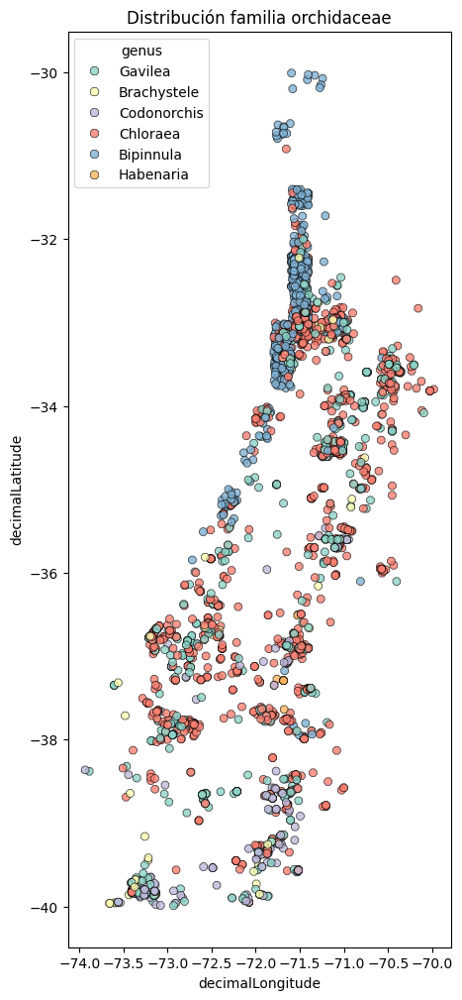

In [ ]:
PlotGeo(df)

In [ ]:
def HistYear(df):
  bins = 2027 - 2019
  sns.histplot(data=df,
              x='year',
              bins = bins,
              palette='Set3',
              kde=True,
  #             hue='month'
              )
  plt.suptitle('Distribución de años')
  plt.show()



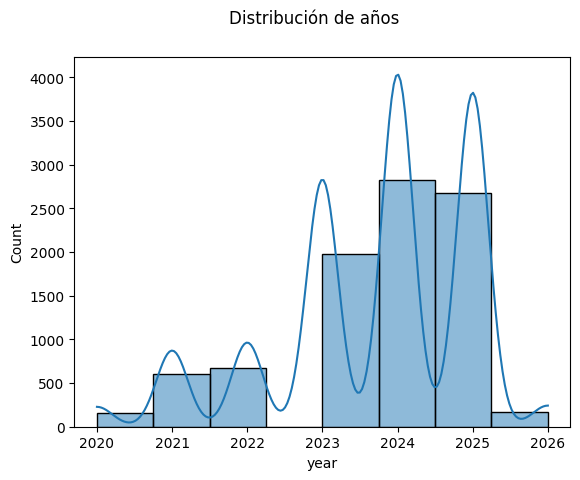

In [ ]:
HistYear(df)

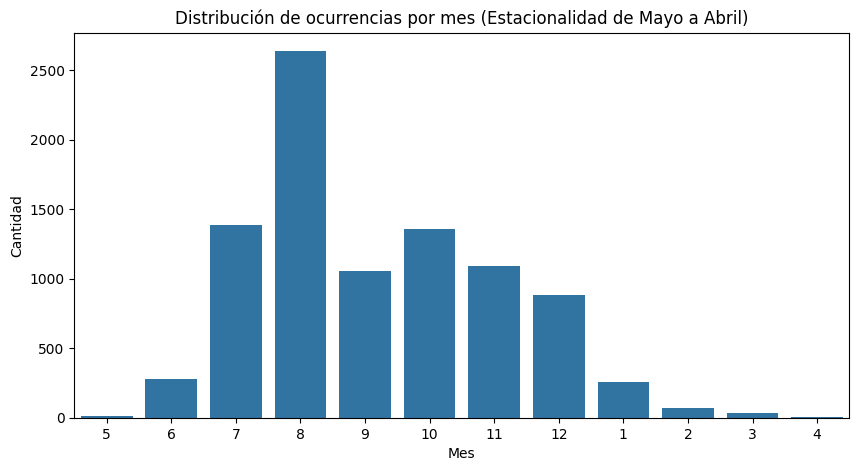

In [ ]:
# Define el orden deseado de los meses (de mayo a abril)
month_order = [5, 6, 7, 8, 9, 10, 11, 12, 1, 2, 3, 4]

# Nos aseguramos de limpiar los valores nulos en 'month' y convertirlos a enteros
plot_df = df.dropna(subset=['month']).copy()
plot_df['month'] = plot_df['month'].astype(int)

# Graficamos usando countplot para mantener el orden exacto de las categorías discretas
plt.figure(figsize=(10, 5))
sns.countplot(data=plot_df, x='month', order=month_order
              )

plt.title('Distribución de ocurrencias por mes (Estacionalidad de Mayo a Abril)')
plt.xlabel('Mes')
plt.ylabel('Cantidad')
plt.show()

In [ ]:
def PlotSeasonGenus(df):
  # Define the Southern Hemisphere seasonal month order (May to April)
  month_order = [5, 6, 7, 8, 9, 10, 11, 12, 1, 2, 3, 4]

  # Clean and prepare the data
  plot_df = df.dropna(subset=['month', 'genus']).copy()
  plot_df['month'] = plot_df['month'].astype(int)

  # Get unique genera ordered by frequency
  genera = plot_df['genus'].value_counts().index
  num_genera = len(genera)

  # Create a grid of subplots (e.g., 3 columns)
  cols = 3
  rows = (num_genera + cols - 1) // cols

  # Set sharex=False so each subplot displays its own x-axis labels
  fig, axs = plt.subplots(rows, cols, figsize=(12, rows * 4), sharex=False)
  axs = axs.flatten()  # Flatten to iterate easily

  for i, genus in enumerate(genera):
      genus_data = plot_df[plot_df['genus'] == genus]

      # Calculate counts for each month in the defined order
      counts = genus_data['month'].value_counts().reindex(month_order, fill_value=0)

      # Convert month keys to strings to ensure categorical treatment in lineplot
      x_labels = [str(m) for m in month_order]

      # Plot as line instead of bar
      sns.lineplot(
          x=x_labels,
          y=counts.values,
          ax=axs[i],
          marker='o'
      )

      axs[i].set_title(f'Genus: {genus} (n={len(genus_data)})')
      axs[i].set_xlabel('Month')
      axs[i].set_ylabel('Count')

  # Hide any unused axes in the grid
  for j in range(i + 1, len(axs)):
      axs[j].axis('off')

  plt.suptitle('Orchid Genus Seasonality in Chile (May to April)', fontsize=16, y=1.02)
  plt.tight_layout()
  plt.show()

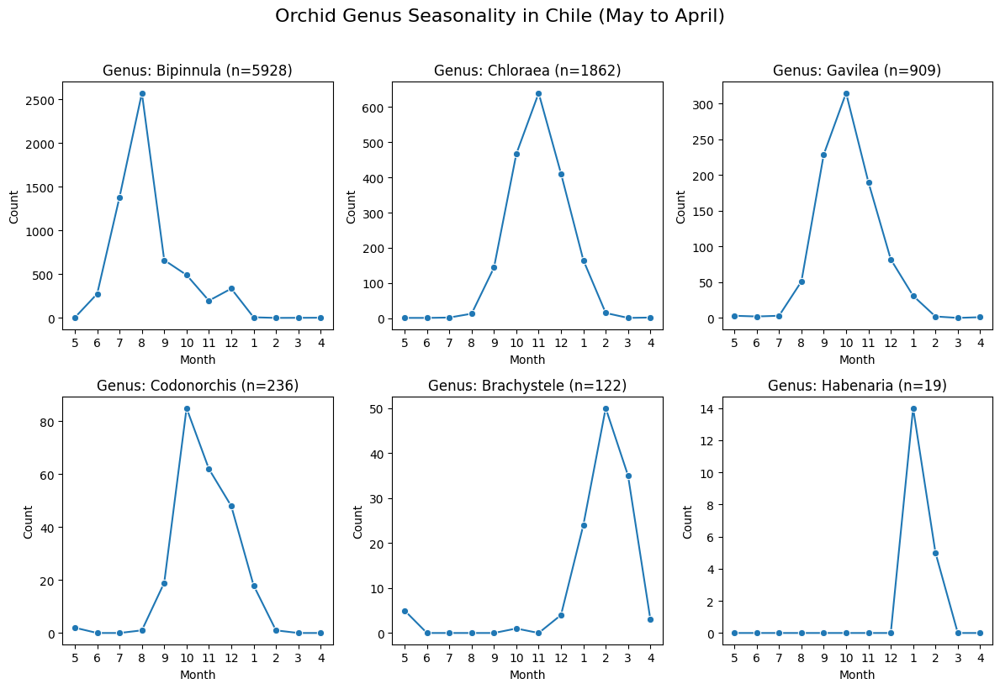

In [ ]:
PlotSeasonGenus(df)

In [ ]:
df_grouped  = df.groupby(by=['genus','species'])['year'].count()
df_grouped.sort_values(ascending=False, inplace=True)
df_grouped

genus        species                 
Bipinnula    Bipinnula fimbriata         5874
Gavilea      Gavilea longibracteata       545
Chloraea     Chloraea bletioides          354
             Chloraea chrysantha          272
             Chloraea gavilu              252
Codonorchis  Codonorchis lessonii         236
Chloraea     Chloraea multiflora          139
Gavilea      Gavilea araucana             134
Chloraea     Chloraea piquichen           129
Brachystele  Brachystele unilateralis     122
Gavilea      Gavilea odoratissima          86
Chloraea     Chloraea galeata              84
             Chloraea alpina               79
             Chloraea nudilabia            71
             Chloraea cristata             69
             Chloraea disoides             66
             Chloraea longipetala          56
Gavilea      Gavilea venosa                55
Chloraea     Chloraea crispa               49
Bipinnula    Bipinnula plumosa             46
Chloraea     Chloraea magellanica          44
Gavilea      Gavilea platyantha            29
             Gavilea lutea                 26
Chloraea     Chloraea barbata              26
             Chloraea cylindrostachya      25
             Chloraea prodigiosa           24
             Chloraea viridiflora          23
             Chloraea tectata              21
Habenaria    Habenaria pumila              19
Chloraea     Chloraea lamellata            18
Gavilea      Gavilea litoralis             16
Chloraea     Chloraea heteroglossa         15
Gavilea      Gavilea glandulifera          10
Chloraea     Chloraea grandiflora          10
Bipinnula    Bipinnula volkmannii           7
Chloraea     Chloraea lechleri              7
             Chloraea philippii             7
             Chloraea bidentata             6
Gavilea      Gavilea chica                  6
Chloraea     Chloraea fonkii                5
             Chloraea cuneata               5
             Chloraea apinnula              2
             Chloraea speciosa              2
Bipinnula    Bipinnula gabriel              1
Chloraea     Chloraea volkmannii            1
Gavilea      Gavilea supralabellata         1
Name: year, dtype: int64

https://biopython.org/docs/dev/Tutorial/chapter_phylo.html

### Cladiograma

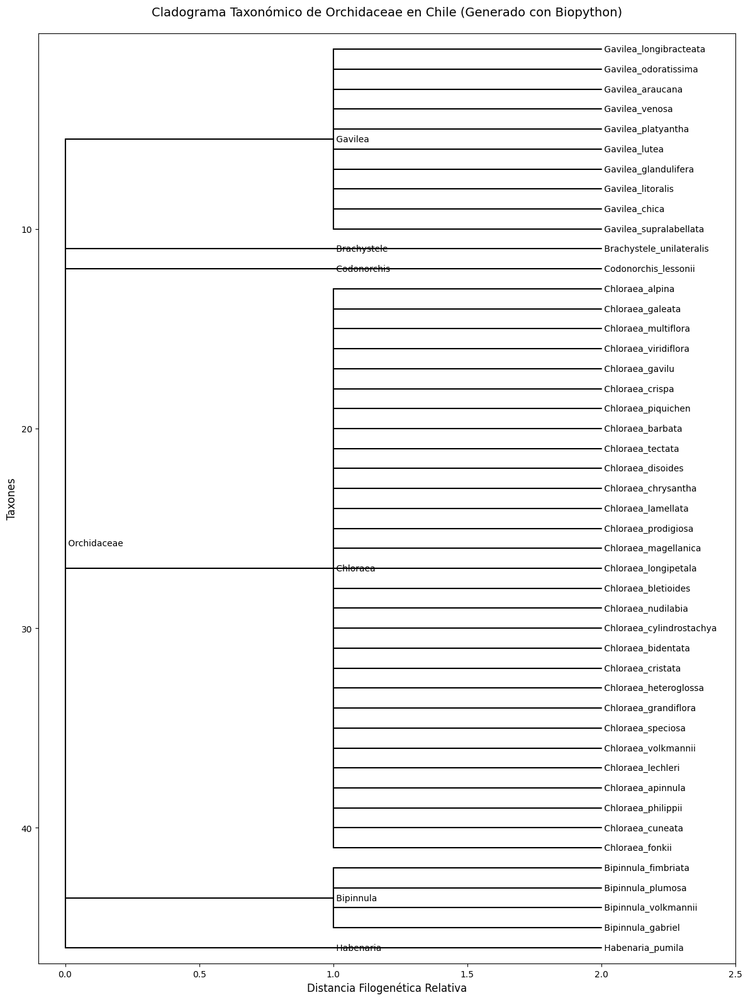

In [ ]:
import io
import matplotlib.pyplot as plt
from Bio import Phylo
from Bio.Phylo.BaseTree import Tree, Clade

# 1. Obtener la taxonomía jerárquica única desde nuestro DataFrame limpio
tax_tree_df = df[['family', 'genus', 'species']].dropna().drop_duplicates(subset=['species'])

# 2. Agrupar la taxonomía jerárquicamente para construir una estructura Newick
# Estructura: ( (Especie1, Especie2)Género1, (Especie3)Género2 )Familia
genus_groups = {}
for _, row in tax_tree_df.iterrows():
    fam = row['family']
    gen = row['genus']
    sp = row['species'].replace(' ', '_') # Los espacios no son válidos en formato estándar Newick sin comillas
    if gen not in genus_groups:
        genus_groups[gen] = []
    genus_groups[gen].append(sp)

# Construir los clados de cada género
genus_strings = []
for genus, species_list in genus_groups.items():
    species_str = ",".join(species_list)
    genus_strings.append(f"({species_str}){genus}")

# Unir todo bajo la raíz de la Familia (Orchidaceae)
newick_tree_str = f"({','.join(genus_strings)})Orchidaceae;"

# 3. Cargar el árbol Newick usando el módulo Phylo de Biopython
tree = Phylo.read(io.StringIO(newick_tree_str), "newick")

# 4. Graficar el cladograma clásico
fig = plt.figure(figsize=(12, 16), dpi=100)
ax = fig.add_subplot(1, 1, 1)

# Dibujar el árbol filogenético/taxonómico clásico
Phylo.draw(tree, axes=ax, do_show=False)

plt.title('Cladograma Taxonómico de Orchidaceae en Chile (Generado con Biopython)', fontsize=14, pad=20)
plt.xlabel('Distancia Filogenética Relativa', fontsize=12)
plt.ylabel('Taxones', fontsize=12)
plt.tight_layout()
plt.show()

## Image

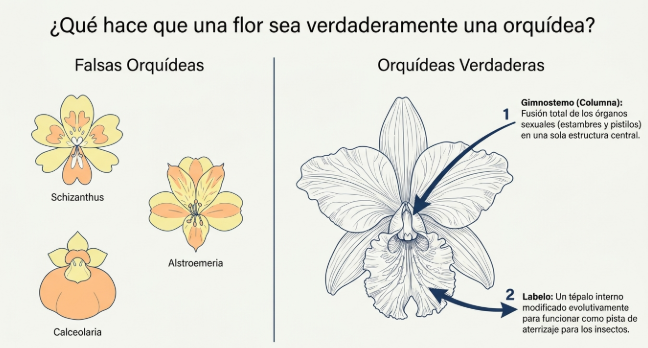

### Identificación del género Chloraea

In [ ]:
df['genus'].unique()

array(['Gavilea', 'Brachystele', 'Codonorchis', 'Chloraea', 'Bipinnula',
       'Habenaria'], dtype=object)

In [ ]:
df_chloraea = df[df['genus'] == 'Chloraea']
df_reduced = df_chloraea[['genus', 'gbifID', 'species']].drop_duplicates(subset=['species'])
df_reduced

,genus,gbifID,species
5,Chloraea,6552883476,Chloraea alpina
7,Chloraea,6552878614,Chloraea galeata
8,Chloraea,6552875752,Chloraea multiflora
9,Chloraea,6552869705,Chloraea viridiflora
11,Chloraea,6552862502,Chloraea gavilu
18,Chloraea,6552734870,Chloraea crispa
19,Chloraea,6552733039,Chloraea piquichen
32,Chloraea,6552397588,Chloraea barbata
38,Chloraea,6552332184,Chloraea tectata
42,Chloraea,6552303738,Chloraea disoides


Starting image extraction and plotting for each unique species...

Attempting to get image for Specie: Chloraea alpina (GBIF ID: 6552883476)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/619243780/original.jpg


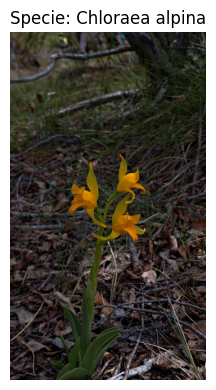


Attempting to get image for Specie: Chloraea galeata (GBIF ID: 6552878614)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/737747466/original.jpg


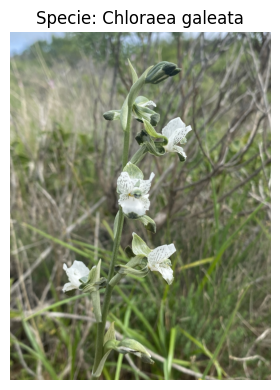


Attempting to get image for Specie: Chloraea multiflora (GBIF ID: 6552875752)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/729967624/original.jpg


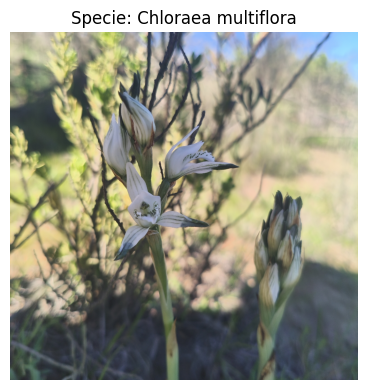


Attempting to get image for Specie: Chloraea viridiflora (GBIF ID: 6552869705)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/599664532/original.jpg


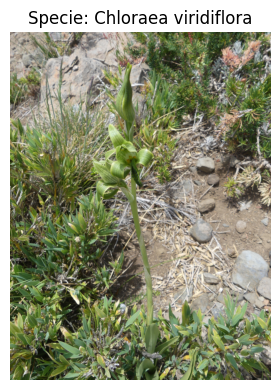


Attempting to get image for Specie: Chloraea gavilu (GBIF ID: 6552862502)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/574325885/original.jpg


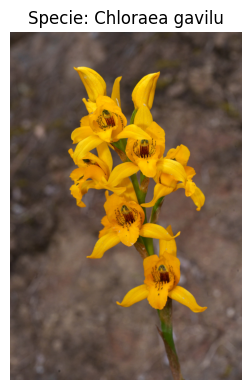


Attempting to get image for Specie: Chloraea crispa (GBIF ID: 6552734870)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/592710956/original.jpg


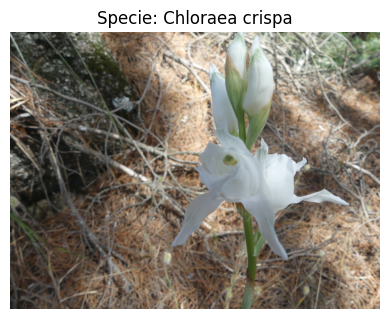


Attempting to get image for Specie: Chloraea piquichen (GBIF ID: 6552733039)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/598402822/original.jpg


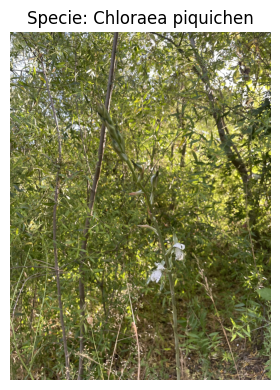


Attempting to get image for Specie: Chloraea barbata (GBIF ID: 6552397588)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/606774770/original.jpg


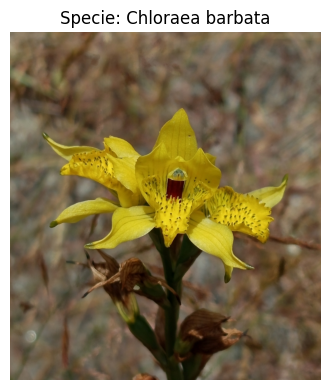


Attempting to get image for Specie: Chloraea tectata (GBIF ID: 6552332184)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/599324160/original.jpg


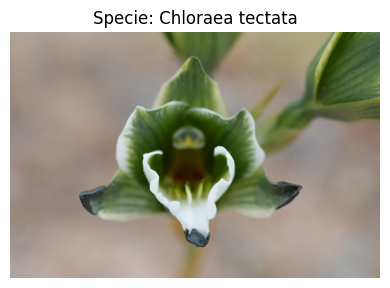


Attempting to get image for Specie: Chloraea disoides (GBIF ID: 6552303738)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/734534807/original.jpg


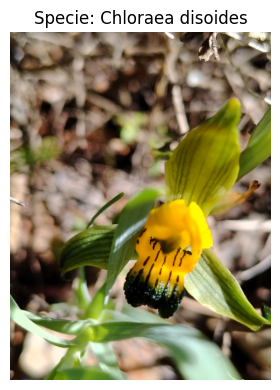


Attempting to get image for Specie: Chloraea chrysantha (GBIF ID: 6552221944)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/735941076/original.jpg


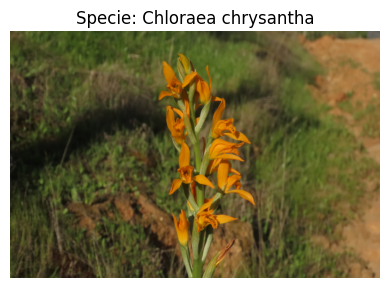


Attempting to get image for Specie: Chloraea lamellata (GBIF ID: 6551942530)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/595539915/original.jpg


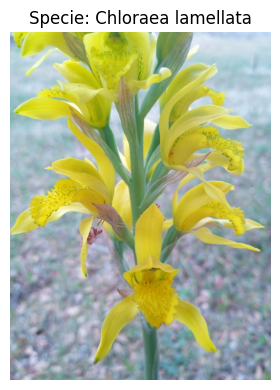


Attempting to get image for Specie: Chloraea prodigiosa (GBIF ID: 6551307700)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/595521283/original.jpg


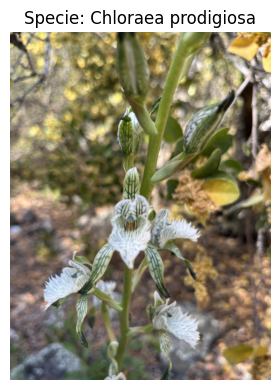


Attempting to get image for Specie: Chloraea magellanica (GBIF ID: 6550921874)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/607314251/original.jpg


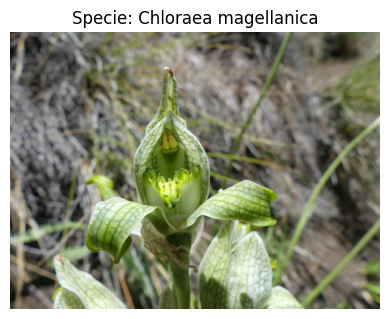


Attempting to get image for Specie: Chloraea longipetala (GBIF ID: 6550895429)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/606768909/original.jpg


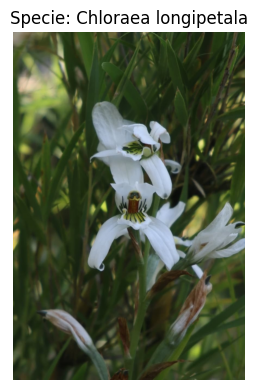


Attempting to get image for Specie: Chloraea bletioides (GBIF ID: 6498232649)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/587486742/original.jpg


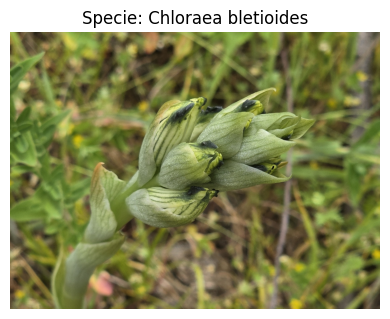


Attempting to get image for Specie: Chloraea nudilabia (GBIF ID: 6441339601)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/597696018/original.jpg


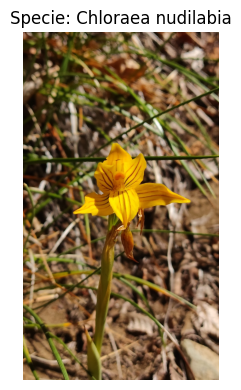


Attempting to get image for Specie: Chloraea cylindrostachya (GBIF ID: 6178993718)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/624219443/original.jpg


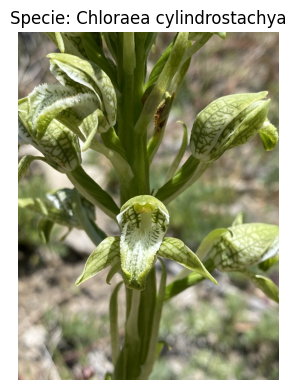


Attempting to get image for Specie: Chloraea bidentata (GBIF ID: 6178538704)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/452338612/original.jpeg


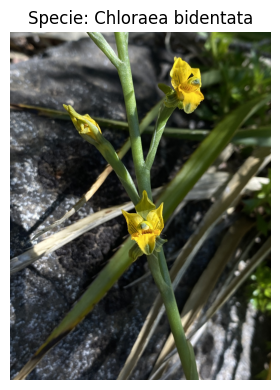


Attempting to get image for Specie: Chloraea cristata (GBIF ID: 6147350623)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/614527648/original.jpg


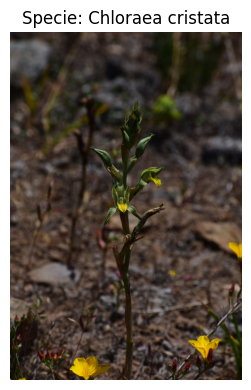


Attempting to get image for Specie: Chloraea heteroglossa (GBIF ID: 6131444059)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/610231689/original.jpg


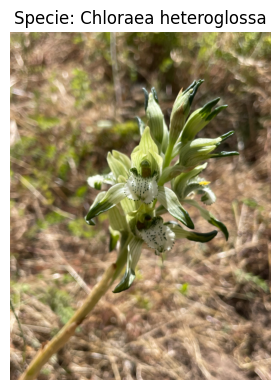


Attempting to get image for Specie: Chloraea grandiflora (GBIF ID: 6131238486)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/607313656/original.jpg


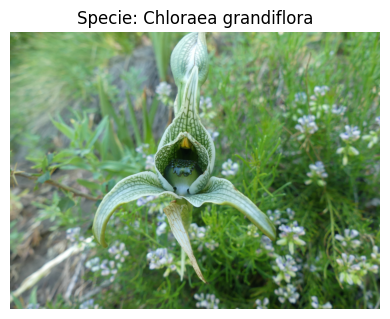


Attempting to get image for Specie: Chloraea speciosa (GBIF ID: 5938246663)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/604676539/original.jpg


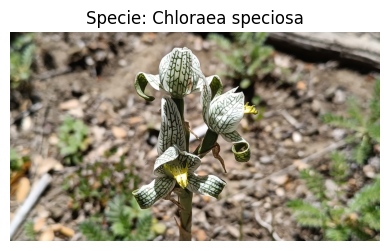


Attempting to get image for Specie: Chloraea volkmannii (GBIF ID: 5935269921)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/599615577/original.jpg


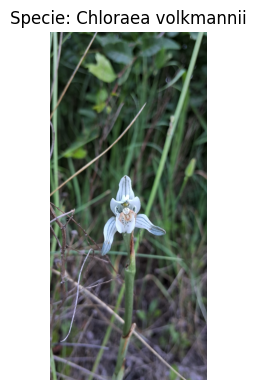


Attempting to get image for Specie: Chloraea lechleri (GBIF ID: 5920211502)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/594224929/original.jpg


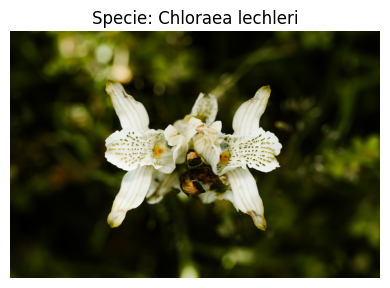


Attempting to get image for Specie: Chloraea apinnula (GBIF ID: 5897150583)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/591881463/original.jpg


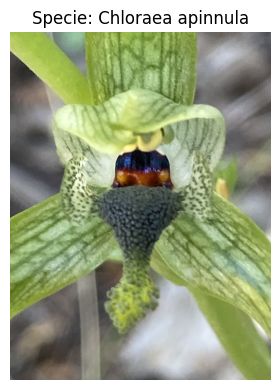


Attempting to get image for Specie: Chloraea philippii (GBIF ID: 5188314485)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/458798875/original.jpg


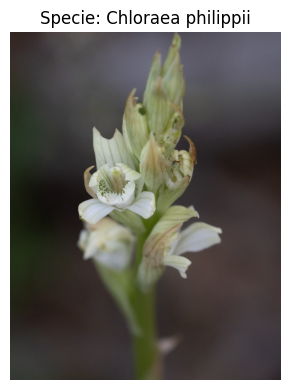


Attempting to get image for Specie: Chloraea cuneata (GBIF ID: 4980266324)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/447164877/original.jpeg


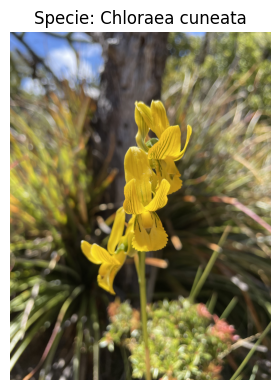


Attempting to get image for Specie: Chloraea fonkii (GBIF ID: 4528013316)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/351545475/original.jpeg


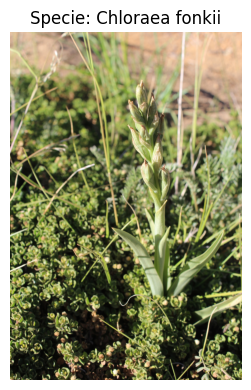


Attempting to get image for Specie: nan (GBIF ID: 3985752959)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/242741704/original.jpeg


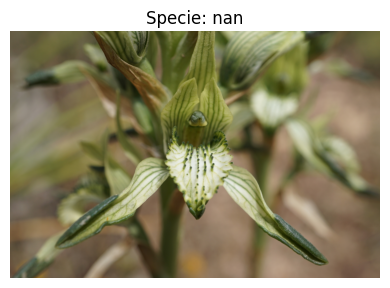


Finished image extraction and plotting.


In [ ]:
# Ensure df_reduced is available. It was created previously in the notebook.
# For robustness, you could uncomment the following line if df_reduced might not be available:
# df_reduced = df[['species','gbifID']].drop_duplicates(subset = ['species'])

import skimage.io

print("Starting image extraction and plotting for each unique species...")

for i in range(len(df_reduced)): # Iterate through the DataFrame of unique species
  gbif_id = df_reduced.iloc[i]['gbifID']
  species = df_reduced.iloc[i]['species']

  print(f"\nAttempting to get image for Specie: {species} (GBIF ID: {gbif_id})")

  image_url = None
  try:
    # Fetch occurrence details from GBIF
    results = occ.get(key=gbif_id)

    if 'media' in results and len(results['media']) > 0: # Check if media exists
        original_url = results['media'][0]['identifier']

        # Check if the URL is an iNaturalist observation page
        if "inaturalist.org/observations/" in original_url:
            print(f"  Parsing iNaturalist page for direct image: {original_url}")
            try:
                # Fetch the iNaturalist page content
                response = requests.get(original_url, timeout=10) # Added a timeout for network request
                response.raise_for_status() # Raise an HTTPError for bad responses (4xx or 5xx)

                # Parse the HTML to find the direct image URL
                soup = BeautifulSoup(response.content, 'html.parser')
                og_image_tag = soup.find('meta', property='og:image')

                if og_image_tag and 'content' in og_image_tag.attrs:
                    image_url = og_image_tag['content']
                    print(f"  Found direct image URL: {image_url}")
                else:
                    print(f"  Warning: Could not find 'og:image' meta tag on iNaturalist page for GBIF ID {gbif_id}.")
            except requests.exceptions.Timeout:
                print(f"  Warning: Request to {original_url} timed out after 10 seconds.")
            except requests.exceptions.RequestException as e:
                print(f"  Warning: Error fetching iNaturalist page {original_url}: {e}")
        else:
            # If not an iNaturalist observation page, assume it's a direct image URL
            image_url = original_url
            print(f"  Using direct image URL: {image_url}")
    else:
        print(f"  No media identifier found for GBIF ID {gbif_id}.")

    if image_url:
        try:
            # Display the image
            fig, ax = plt.subplots(1, 1, figsize=(4, 4))
            image = skimage.io.imread(image_url)
            ax.imshow(image)
            ax.axis('off')
            ax.set_title(f"Specie: {species}")
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f"  Error loading or displaying image from {image_url}: {e}")
    else:
        print(f"  No image available to display for specie: {species} (GBIF ID: {gbif_id}).")

  except Exception as e:
    print(f"  An unexpected error occurred while processing GBIF ID {gbif_id} (specie: {species}): {e}")

print("\nFinished image extraction and plotting.")

### Extracción imagen

In [ ]:
def get_urlimage(genus):
  specimen = df_reduced[df_reduced['species'] == genus]
  id = specimen['gbifID'].iloc[0]
  speciess = specimen['species'].iloc[0]
  results = occ.get(key=id)
  original_url = results['media'][0]['identifier']
  return original_url, speciess

In [ ]:
original_url, speciess = get_urlimage('Chloraea gavilu')

In [ ]:
def read_image(original_url):
  image = io.imread(original_url)
  return image


In [ ]:
image = skimage.io.imread(original_url)

In [ ]:
def plot_image(i,s):
  fig, ax = plt.subplots(1, 1, figsize=(6, 6))
  ax.imshow(i)
  plt.suptitle(s)
  ax.axis('off')
  plt.tight_layout()
  plt.show()

  print(f'shape: {image.shape}')


### Visualización simple

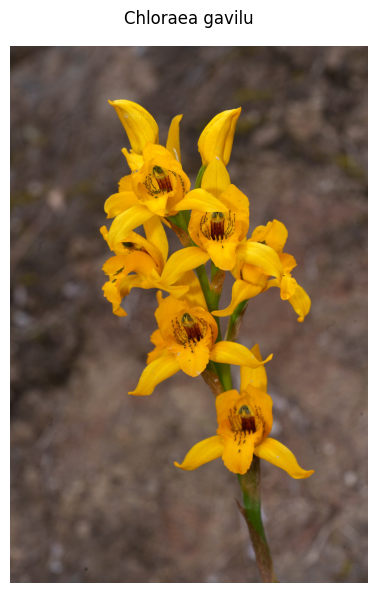

shape: (2048, 1365, 3)


In [ ]:
plot_image(image,speciess)

### División de canales

In [ ]:
def split_channels(image):
  i_r = image[:,:,0]
  i_g = image[:,:,1]
  i_b = image[:,:,2]

  return [i_r, i_g, i_b]

In [ ]:
def split_channels_flatten(image):
  i_r_flatten = image[:,:,0].flatten()
  i_g_flatten = image[:,:,1].flatten()
  i_b_flatten = image[:,:,2].flatten()

  return [i_r_flatten, i_g_flatten, i_b_flatten]

In [ ]:
def plot_channels(image):
  image_red, image_green, image_blue = split_channels(image)
  fig, axs = plt.subplots(1, 3, figsize=(15, 5))
  axs[0].imshow(image_red, cmap='Reds')
  axs[1].imshow(image_green, cmap='Greens')
  axs[2].imshow(image_blue, cmap='Blues')
  axs[0].axis('off')
  axs[1].axis('off')
  axs[2].axis('off')
  axs[0].set_title('Canal R')
  axs[1].set_title('Canal G')
  axs[2].set_title('Canal B')
  plt.show()

In [ ]:
def plot_channel_hist(image):
  image_red, image_green, image_blue = split_channels_flatten(image)
  bins = 24

  fig, axs = plt.subplots(1, 3, figsize=(15, 5))

  sns.histplot(image_red, color='red',kde=True, ax=axs[0], bins=bins)
  sns.histplot(image_green, color='green',kde=True, ax=axs[1], bins=bins)
  sns.histplot(image_blue, color='blue',kde=True, ax=axs[2], bins=bins)
  axs[0].axis('off')
  axs[1].axis('off')
  axs[2].axis('off')
  axs[0].set_title('Canal R')
  axs[1].set_title('Canal G')
  axs[2].set_title('Canal B')
  plt.show()

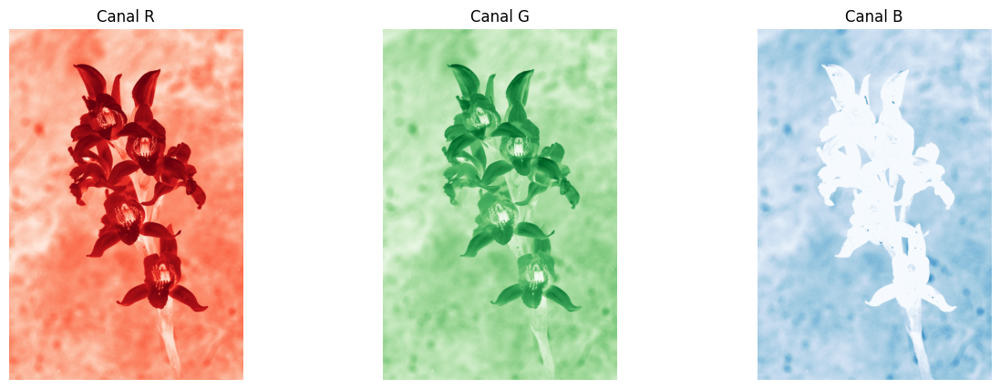

In [ ]:
plot_channels(image)

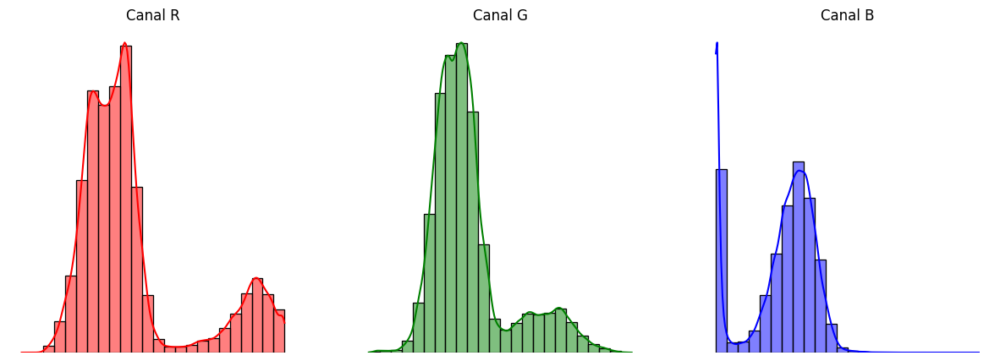

In [ ]:
plot_channel_hist(image)

### Segmentación de colores

[IMG01_SimpleColorSegmentation](https://colab.research.google.com/drive/1gfSdlVgzd3abygf8XB0I2F62rpzlh8SK#scrollTo=HKzfhtR9P9ef). Domingo Mery

In [ ]:
def HowIs(img):
  print('size = ',img.shape)
  print('max  = ',np.max(img))
  print('min  = ',np.min(img))

In [ ]:
Icv = cv2.resize(image, (720, 720))

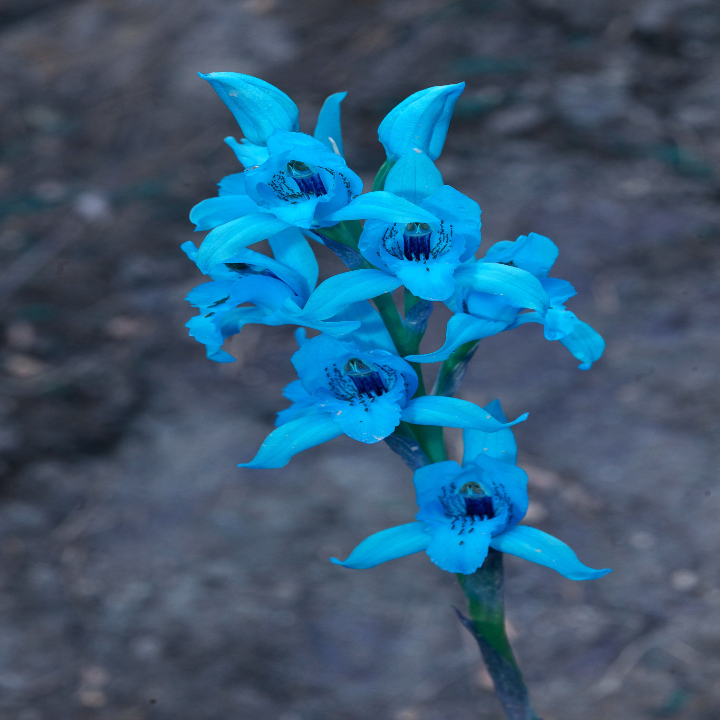

size =  (720, 720, 3)
max  =  255
min  =  0


In [ ]:
cv2_imshow(Icv)
HowIs(Icv)

Revisar

In [ ]:
def InvertColor(Icv):
  I2 = Icv[:,:,[0,1,2]]             # BGR to RGB conversion
  fig, ax = plt.subplots(1, 2, figsize=(12, 6))
  ax[0].imshow(Icv)
  ax[0].set_title("Original (RGB)")
  ax[0].axis('off')

  ax[1].imshow(I2)
  ax[1].set_title("Inverted (---)")
  ax[1].axis('off')

  plt.show()
  return I2

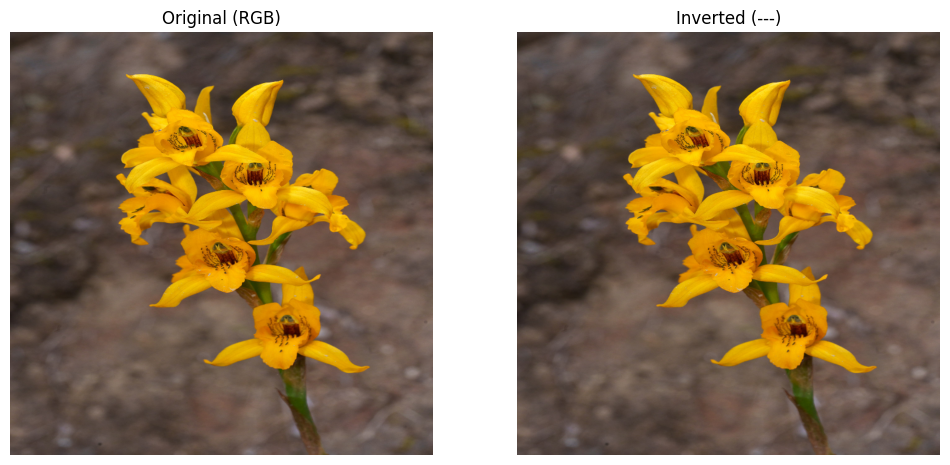

In [ ]:
I2 = InvertColor(Icv)

In [ ]:
def SeparateChannel(I2):
  R = I2[:,:,0]
  G = I2[:,:,1]
  B = I2[:,:,2]
  RGB = np.concatenate((R,G,B),axis=1)
  cv2_imshow(RGB)

  return [R,G,B]

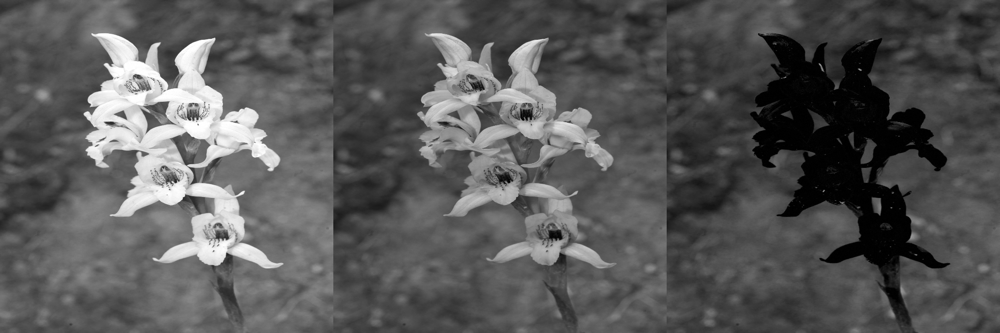

In [ ]:
R,G,B = SeparateChannel(I2)

size =  (720, 720)
max  =  250
min  =  22


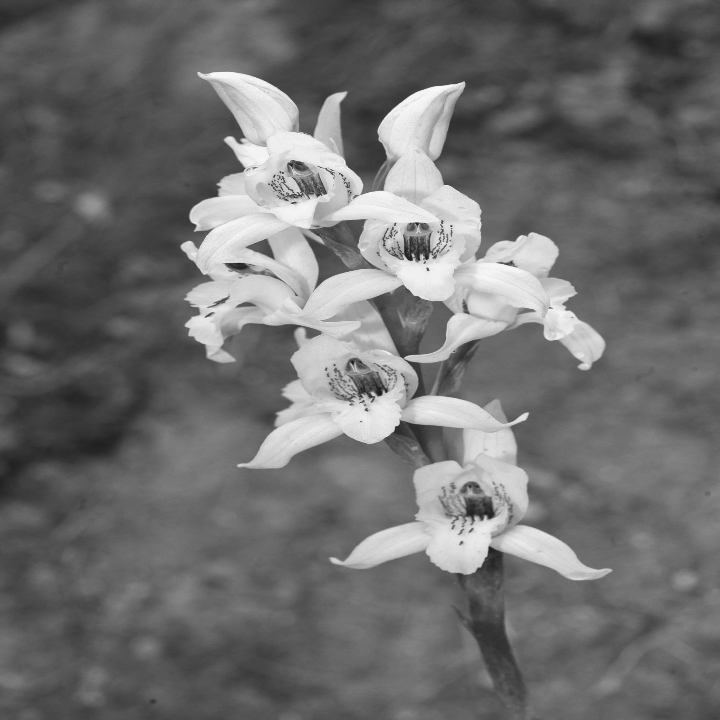

In [ ]:
Rd = R.astype(float)
Gd = G.astype(float)
Bd = B.astype(float)
# weighted average
#k  = (1/3,1/3,1/3)
k  = (0.75,0.25,0)
Zd = k[0]*Rd+k[1]*Gd+k[2]*Bd
Z  = Zd.astype(int)
HowIs(Z)
cv2_imshow(Z)

### Segmentación de canales RGB

In [ ]:
def Segmentate(R,G,B,tR=128,tG=128,tB=40):
  Sr = R>tR
  Sg = G>tG
  Sb = B<tB
  Srgb = np.concatenate((Sr,Sg,Sb),axis=1)
  cv2_imshow(Srgb*255)

  ## integrate three channels
  Srg = np.logical_and(Sr,Sg)
  S   = np.logical_and(Srg,Sb)
  cv2_imshow(S*255)

  return [Sr,Sg,Sb, S]

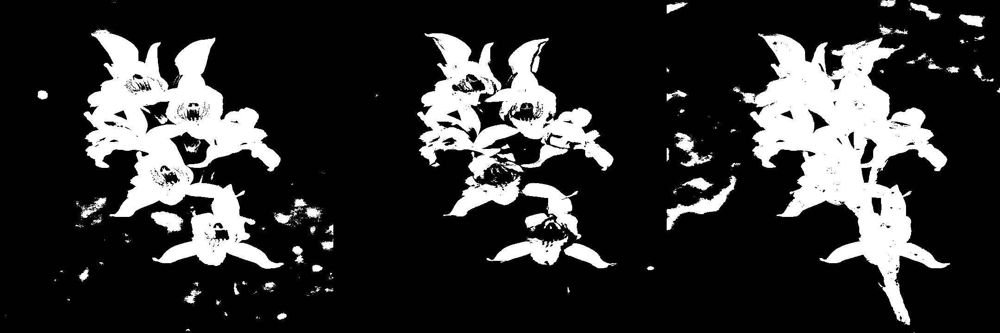

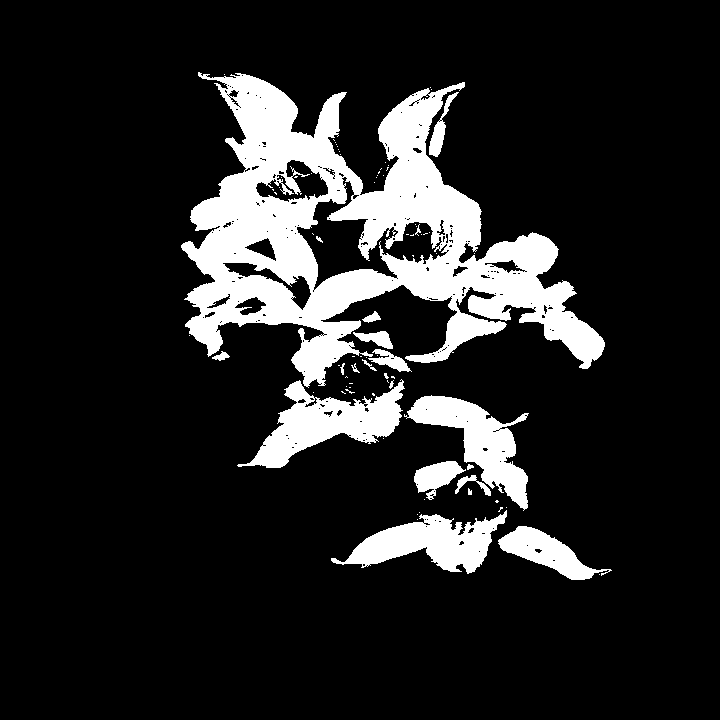

In [ ]:
Sr, Sg, Sb, S = Segmentate(R,G,B)

In [ ]:
def SegmentateIsolatedPixel(S):
  (N,M) = S.shape
  Q = S
  for i in range(N):
    s = np.sum(S[i,:])
    if s<20:
      Q[i,:] = 0
  cv2_imshow(Q*255)

  return Q

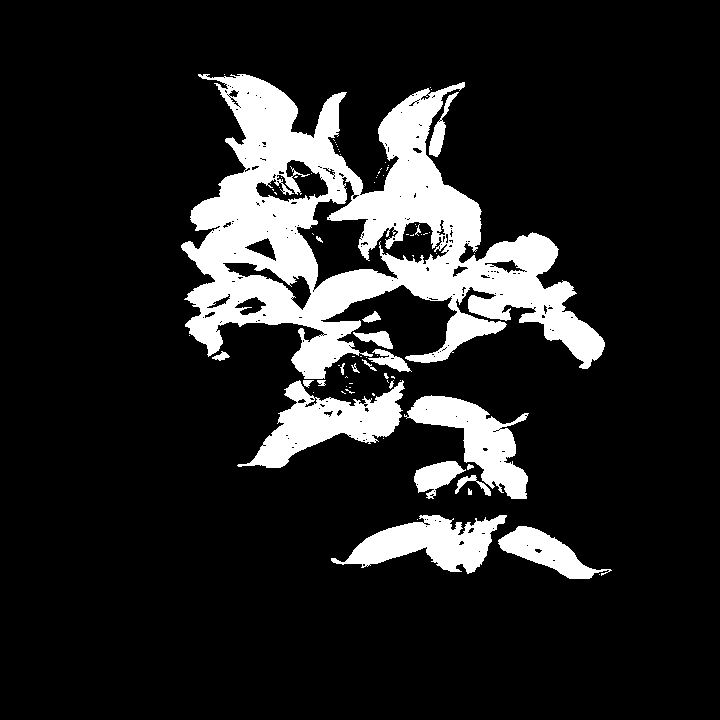

In [ ]:
Q = SegmentateIsolatedPixel(S)

In [ ]:
imin = 1000
imax = 0
jmin = 1000
jmax = 0
for i in range(N):
  for j in range(M):
    if Q[i,j]>0:
      if i<imin:
        imin = i
      if i>imax:
        imax = i
      if j<jmin:
        jmin = j
      if j>jmax:
        jmax = j

### Identificación del objeto

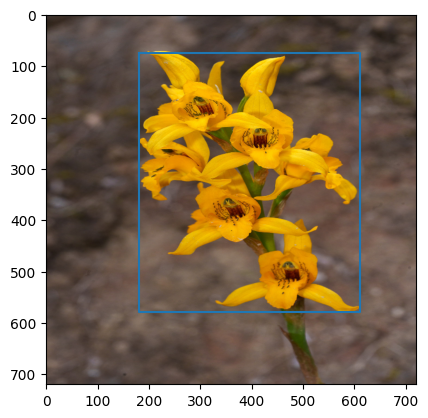

In [ ]:
y = [imin,imin,imax,imax,imin]
x = [jmin,jmax,jmax,jmin,jmin]
plt.imshow(I2)
plt.plot(x,y)
plt.show()

### Contorno del objeto

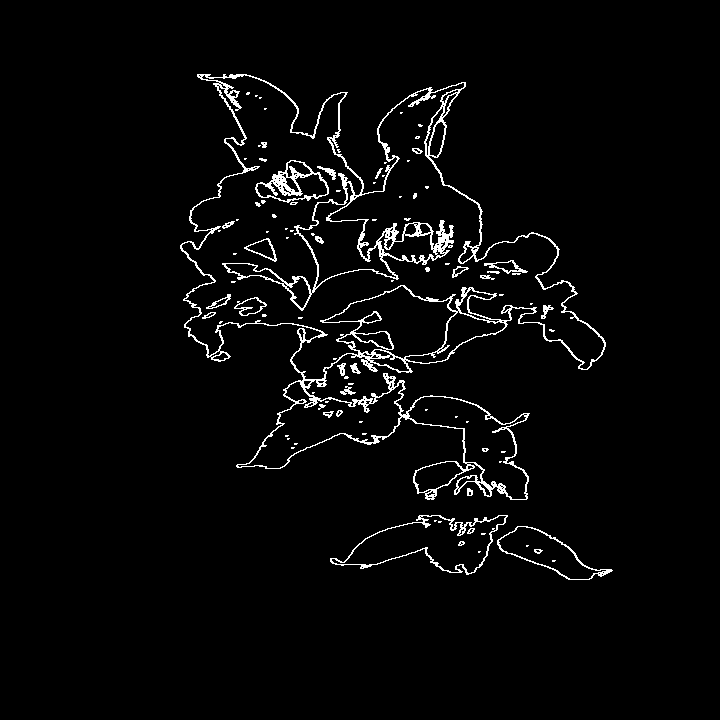

In [ ]:
E = np.zeros((N,M),np.uint8)
for i in range(N):
  for j in range(1,M):
    if Q[i,j]!=Q[i,j-1]:
      E[i,j]   = 1
      E[i,j-1] = 1
for i in range(1,N):
  for j in range(M):
    if Q[i-1,j]!=Q[i,j]:
      E[i,j]   = 1
      E[i,j-1] = 1
cv2_imshow(E*255)


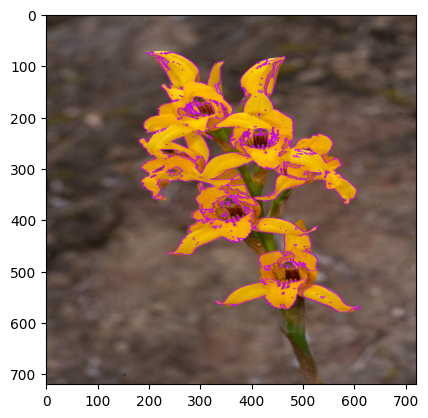

In [ ]:
for i in range(N):
  for j in range(M):
    if E[i,j]==1:
      Icv[i,j,:] = [200,0,255]
Icv = Icv[:,:,[0,1,2]]             # BGR to RGB conversion
plt.imshow(Icv)
plt.show()


### Otras técnicas de segmentación

In [ ]:
I_gray = cv2.cvtColor(I2, cv2.COLOR_RGB2GRAY)

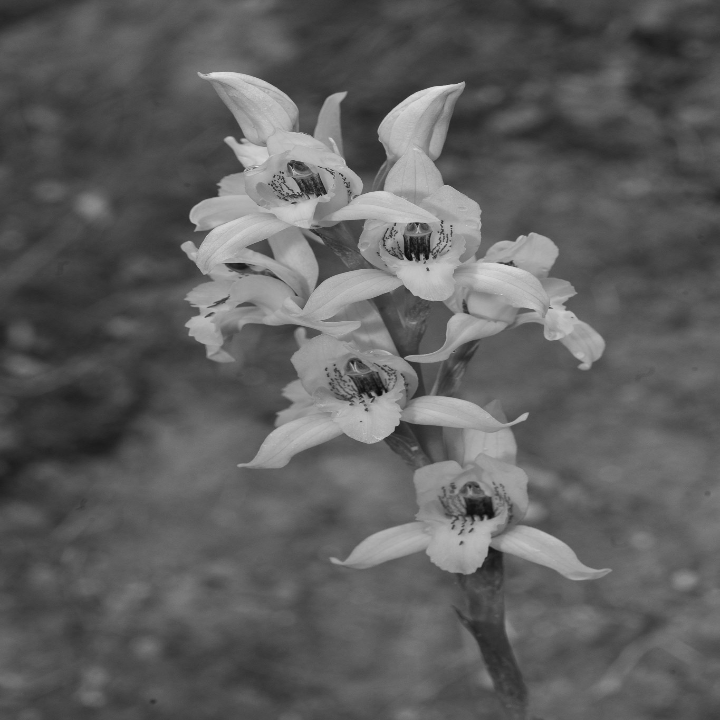

In [ ]:
cv2_imshow(I_gray)


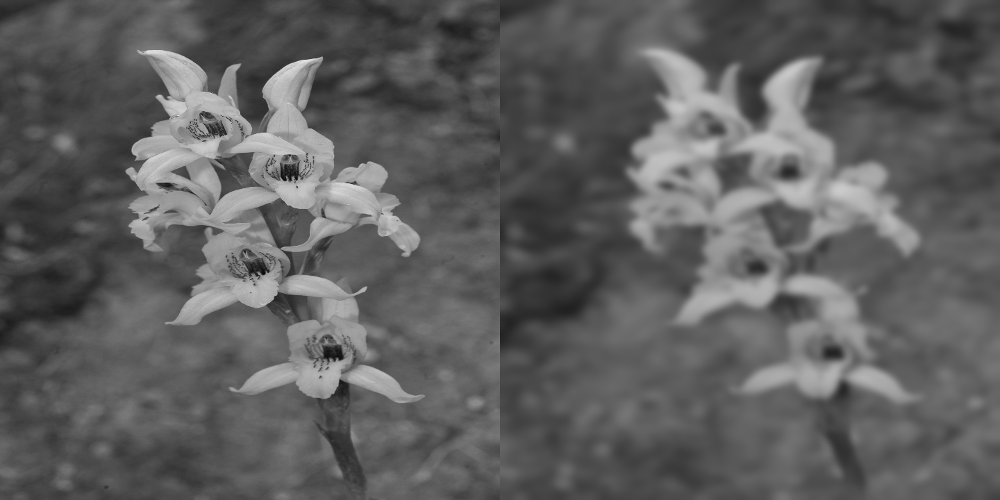

In [ ]:
# FGaussian Filtering
s      = 39
kernel = cv2.getGaussianKernel(s, s/8.5)        # Gaussian s x 1  (s = size, s/8.5 = sigma)
window = np.outer(kernel, kernel.transpose())   # Gaussian s x s pixels
L      = cv2.filter2D(I_gray,-1,window)
Z      = np.concatenate((I_gray ,L),axis=1)
cv2_imshow(Z)

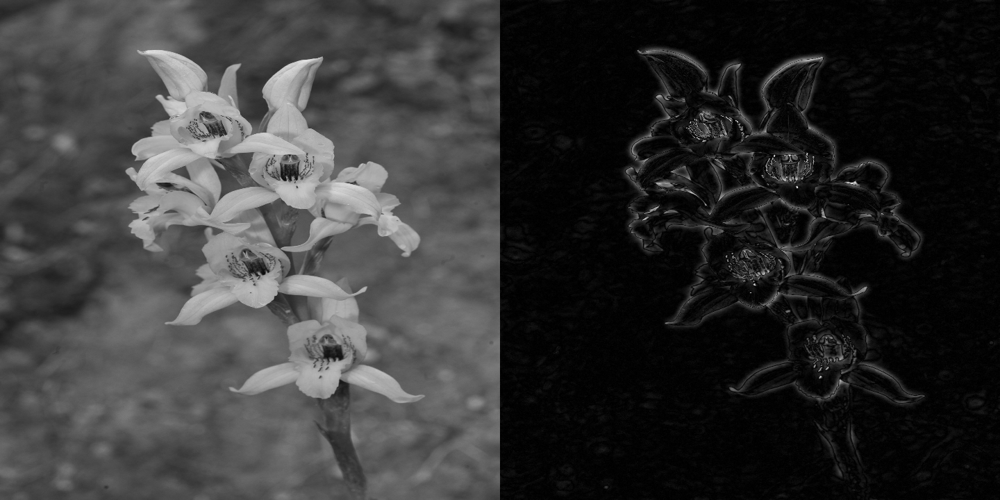

In [ ]:
# High Pass Filtering
Id = I_gray.astype(float)
Ld = L.astype(float)
Hd = Id-Ld

# Visualization
H = np.abs(Hd)
H = H-np.min(H)
H = H/np.max(H)*255
Z = np.concatenate((I_gray,H),axis=1)
cv2_imshow(Z)

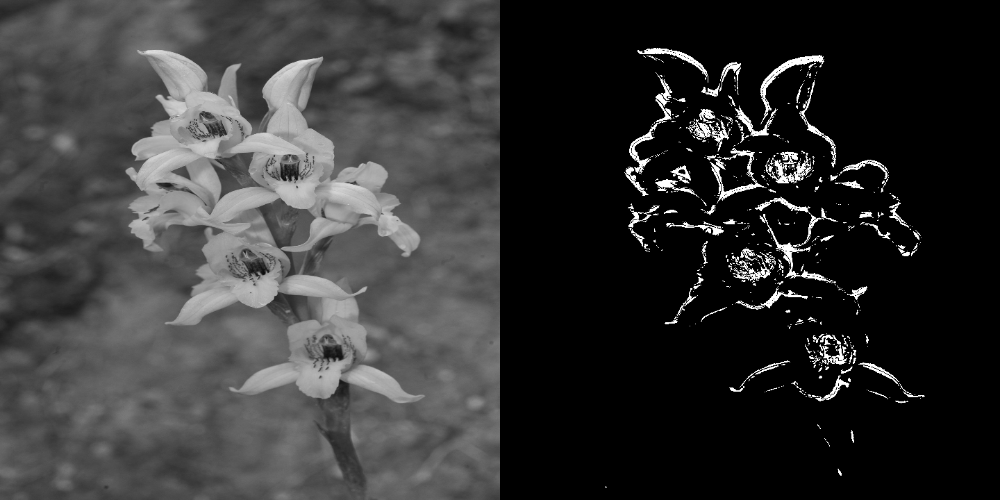

In [ ]:
# Edge detection using High Pass Filtering
E = (H>50)*255
Z = np.concatenate((I_gray,E),axis=1)
cv2_imshow(Z)

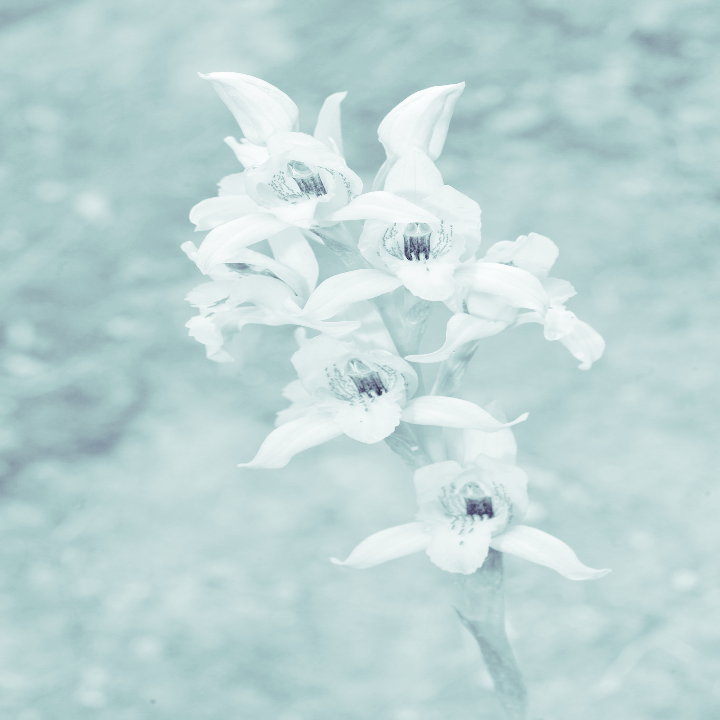

In [ ]:
L = np.log(G+1)
L = L/np.max(L)*255
Li = L.astype(np.uint8)


Lc = cv2.applyColorMap(Li, cv2.COLORMAP_BONE)

cv2_imshow(Lc)

### Cluster de colores

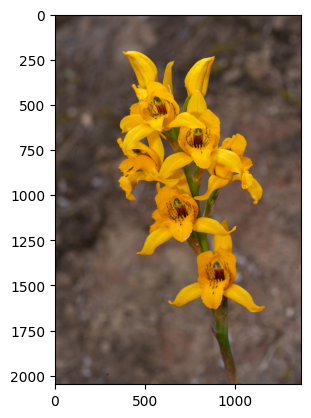

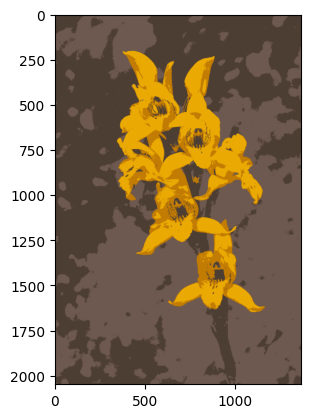

In [ ]:
# convert to RGB
image2 = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image2 = image2[:,:,[2,1,0]]             # BGR to RGB conversion

plt.imshow(image2)
plt.show()

# reshape the image to a 2D array of pixels and 3 color values (RGB)
pixel_values = image2.reshape((-1, 3))
# convert to float
pixel_values = np.float32(pixel_values)

# define stopping criteria
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

# Define the number of clusters for K-Means (K is an integer)
k = 4
compactness, labels, (centers) = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# convert back to 8 bit values
centers = np.uint8(centers)

# flatten the labels array
labels = labels.flatten()

# convert all pixels to the color of the centroids
segmented_image = centers[labels]

# reshape back to the original image dimension
segmented_image = segmented_image.reshape(image2.shape)

# show the image
plt.imshow(segmented_image)
plt.show()